# Set up

In [1]:
SPARK_CONNECT_HOST = "localhost" # if running via an SSH tunnel
#SPARK_CONNECT_HOST = "spark-connector-0-driver-svc" # for running in the Kubernetes cluster

# Connect to Spark

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("test").remote(f"sc://{SPARK_CONNECT_HOST}:15002").getOrCreate()
print("session created")

session created


# Get the data

Take patient data from AWS and bed occupancy data from GCP and join them.

Note that these tables need to be registered first - see instructions in the docs at [README.md](https://github.com/emrys-health/afon-core/blob/main/afon-infra/README.md).

*However*, if you re-create the synthetic data using:
```shell
cd afon-samples/
export MAVEN_OPTS="--add-exports=java.base/sun.nio.ch=ALL-UNNAMED"
mvn -Dexec.mainClass=health.emrys.afon.samples.PatientDataMain exec:java
```
then the tables will be automatically registered with the cluster's Polaris.

In [4]:
NAMESPACE = "samples2"
patients = spark.read.table(f"aws.{NAMESPACE}.patients")
occupancy = spark.read.table(f"gcp.{NAMESPACE}.occupancy")
data = patients.join(occupancy, patients.id == occupancy.id)
data.show()

+---+---+---+-------+
| id|age| id|numDays|
+---+---+---+-------+
|  0|  0|  0|      0|
|  1|  1|  1|      1|
|  2|  2|  2|      0|
|  3|  3|  3|      3|
|  4|  4|  4|      1|
|  5|  5|  5|      4|
|  6|  6|  6|      5|
|  7|  7|  7|      7|
|  8|  8|  8|      6|
|  9|  9|  9|      2|
| 10| 10| 10|      1|
| 11| 11| 11|     11|
| 12| 12| 12|      6|
| 13| 13| 13|      0|
| 14| 14| 14|     11|
| 15| 15| 15|      7|
| 16| 16| 16|     13|
| 17| 17| 17|      4|
| 18| 18| 18|     16|
| 19| 19| 19|     12|
+---+---+---+-------+
only showing top 20 rows


# Find the Pearson Correlation between the Features

In [14]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

featuresColName = "features"
features = ["age", "numDays"]
assembler = (VectorAssembler()
        .setInputCols(features)
        .setOutputCol(featuresColName))
df = assembler.transform(data)

r1 = Correlation.corr(df, featuresColName).head()
dm = r1[0]
print("Pearson correlation matrix:\n" + str(dm))

Pearson correlation matrix:
DenseMatrix([[1.        , 0.65423597],
             [0.65423597, 1.        ]])


# Plot the Pearson Correlation

In [7]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 4.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 4.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 4.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 4.9 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


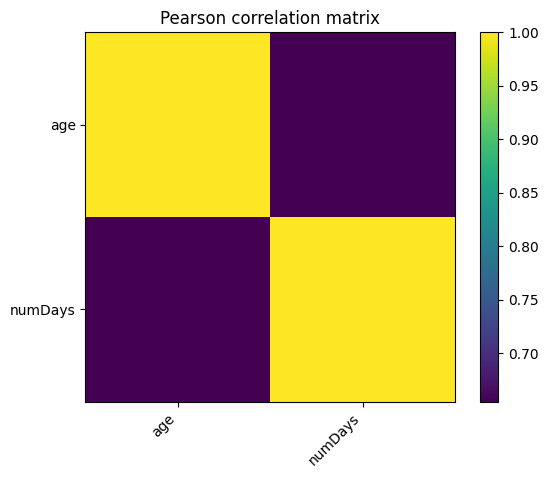

In [13]:
import matplotlib.pyplot as plt
import numpy as np

plt.imshow(dm.toArray())
plt.colorbar()
plt.title("Pearson correlation matrix")
plt.xticks(ticks=np.arange(len(features)), labels=features, rotation=45, ha="right")
plt.yticks(ticks=np.arange(len(features)), labels=features)
plt.show()